In [7]:
#Cell 1: Imports & Drive Mount

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')
print("Google Drive mounted successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted successfully!


In [ ]:
# Cell 2: Load Updated Dataset & Split

# Update file path to the new file Shaima generated
file_path = '/content/drive/MyDrive/Tech Fem team - SIC capstone project/Week 1/Data Pipeline/data/processed/crude_weekly_full_with_implied_lags.csv'

# If loading CSV:
df = pd.read_csv(file_path)

# Handle date column
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

# Drop trailing row where target is missing (matches Shaima's common.py handling)
last_valid_idx = df['target_next_week_change'].last_valid_index()
df = df.loc[:last_valid_idx].reset_index(drop=True)

# Reserve last 104 weeks (2 years) as test set
TEST_WEEKS = 104
train_df = df.iloc[:-TEST_WEEKS].copy()
test_df = df.iloc[-TEST_WEEKS:].copy()

print(f"Full Range : {df['date'].min().strftime('%Y-%m-%d')} to {df['date'].max().strftime('%Y-%m-%d')} ({len(df)} weeks)")
print(f"Train Set  : {train_df['date'].min().strftime('%Y-%m-%d')} to {train_df['date'].max().strftime('%Y-%m-%d')} ({len(train_df)} weeks)")
print(f"Test Set   : {test_df['date'].min().strftime('%Y-%m-%d')} to {test_df['date'].max().strftime('%Y-%m-%d')} ({len(test_df)} weeks)")

Dropping 1 trailing row(s) with unknown future target.
Full Range : 1991-01-04 to 2026-09-11 (1863 weeks)
Train Set  : 1991-01-04 to 2024-09-13 (1759 weeks)
Test Set   : 2024-09-20 to 2026-09-11 (104 weeks)


In [ ]:
# Cell 3: Generate Baseline Predictions & Calculate Metrics
import os

# 1. Naive (Persistence): Next week = Current week (y_hat_{t+1} = y_t)
test_df['pred_naive'] = test_df['stocks_change']

# 2. Seasonal Naive: Next week = 52 weeks ago
df['pred_seasonal_naive'] = df['target_next_week_change'].shift(52)
test_df['pred_seasonal_naive'] = df.loc[test_df.index, 'pred_seasonal_naive']

# 3. Mean Baseline: Predicts historical train mean
train_mean = train_df['target_next_week_change'].mean()
test_df['pred_mean'] = train_mean

# Helper evaluation function
def eval_model(y_true, y_pred, name):
    return {
        'Model': name,
        'MAE (kb)': round(mean_absolute_error(y_true, y_pred), 2),
        'RMSE (kb)': round(np.sqrt(mean_squared_error(y_true, y_pred)), 2),
        'R² Score': round(r2_score(y_true, y_pred), 4)
    }

# Compute metrics
baseline_results = [
    eval_model(test_df['target_next_week_change'], test_df['pred_naive'], 'Naive (Persistence)'),
    eval_model(test_df['target_next_week_change'], test_df['pred_seasonal_naive'], 'Seasonal Naive (52-Wk)'),
    eval_model(test_df['target_next_week_change'], test_df['pred_mean'], 'Historical Mean')
]

baseline_df = pd.DataFrame(baseline_results)
print("=== UPDATED BASELINE METRICS (104-WEEK TEST SET) ===")
display(baseline_df)

# Save updated baseline_metrics.csv locally and to Drive
output_dir = '/content/drive/MyDrive/Tech Fem team - SIC capstone project/Week 2/4. Model Training and Optimization/4.1 Naive & seasonal naive baseline model'
os.makedirs(output_dir, exist_ok=True)

save_metrics_path = os.path.join(output_dir, 'baseline_metrics.csv')
baseline_df.to_csv(save_metrics_path, index=False)
baseline_df.to_csv('baseline_metrics.csv', index=False)
print(f"Metrics saved successfully to: {save_metrics_path}")

=== BASELINE METRICS (104-WEEK TEST SET) ===


,Model,MAE (kb),RMSE (kb),R² Score
0,Naive (Persistence),4730.71,6360.17,-0.6868
1,Seasonal Naive (52-Wk),4800.43,6144.67,-0.5744


Metrics saved successfully to: /content/drive/MyDrive/Tech Fem team - SIC capstone project/Week 2/4. Model Training and Optimization/4.1 Naive & seasonal naive baseline model/baseline_metrics.csv


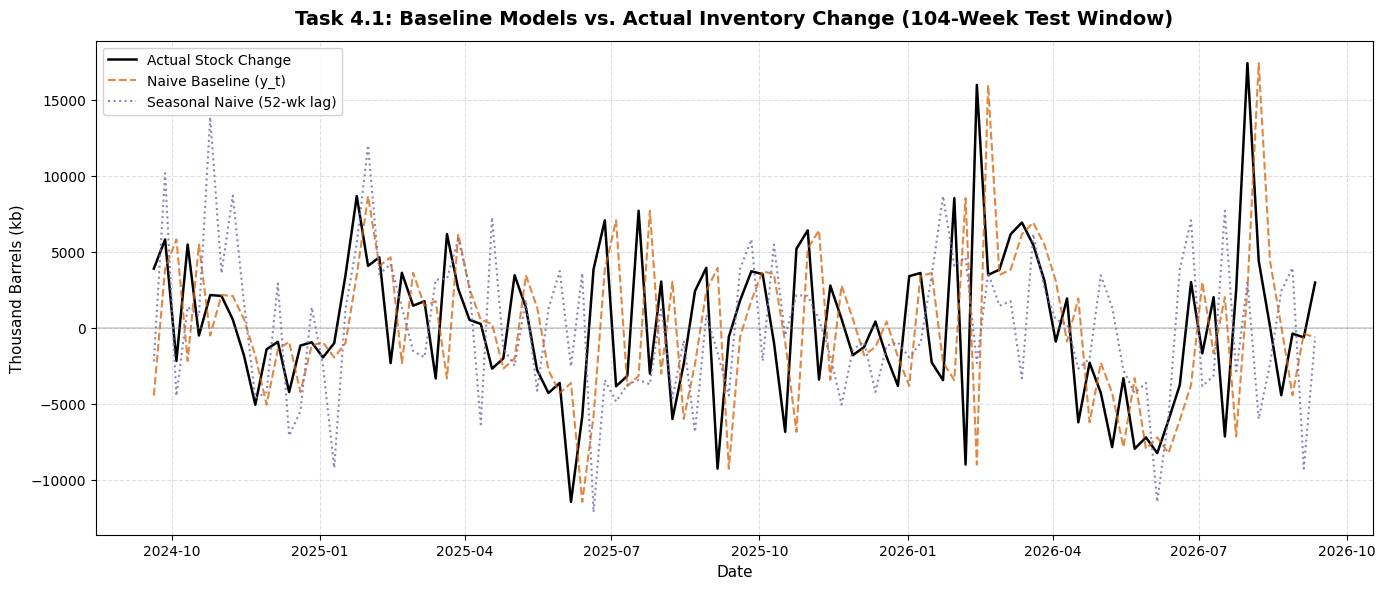

In [11]:
#Cell 4: Visualization

plt.figure(figsize=(14, 6))
plt.plot(test_df['date'], test_df['target_next_week_change'], label='Actual Stock Change', color='black', linewidth=1.8)
plt.plot(test_df['date'], test_df['pred_naive'], label='Naive Baseline (y_t)', linestyle='--', alpha=0.75, color='#d95f02')
plt.plot(test_df['date'], test_df['pred_seasonal_naive'], label='Seasonal Naive (52-wk lag)', linestyle=':', alpha=0.85, color='#7570b3')

plt.axhline(0, color='gray', linestyle='-', alpha=0.3)
plt.title('Task 4.1: Baseline Models vs. Actual Inventory Change (104-Week Test Window)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Date', fontsize=11)
plt.ylabel('Thousand Barrels (kb)', fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()